# 04 — Anomaly analysis

Residual computation, anomaly-score construction, the ablation study, and evaluation against weak labels and synthetic shocks (Req 7.4). Requires `reports/tables/forecast_sarima_aic.csv` from notebook 03. Narrative: `reports/anomaly_analysis.md`.

*Data: CEDA Agri Market Data, Centre for Economic Data and Analysis (CEDA), Ashoka University; original source DMI, Ministry of Agriculture and Farmers Welfare (Agmarknet).*

In [1]:
import os, sys
from pathlib import Path
# Run from the repository root so `src` and configured relative paths resolve
root = Path.cwd()
while not (root / "configs" / "config.json").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import load_config, resolve_path
cfg = load_config()
tables = resolve_path(cfg["paths"]["tables_dir"])
figs = resolve_path(cfg["paths"]["figures_dir"])
print("Repository root:", root)

Repository root: D:\MY works\CropCast


In [2]:
from src.anomaly_detection.run import AnomalyRunner
summary = AnomalyRunner(cfg).run()
{k: v for k, v in summary.items() if k != 'event_classes'}

warning (first occurrence; all occurrences are counted in the run manifest): ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals [D:\MY works\CropCast\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737]


warning (first occurrence; all occurrences are counted in the run manifest): RuntimeWarning: All-NaN slice encountered [D:\MY works\CropCast\src\anomaly_detection\run.py:212]


{'onion_maharashtra': {'sarima_order': {'p': 0, 'q': 2, 'P': 1, 'Q': 1},
  'scored_days': 2077,
  'first_scored_date': '2017-03-29',
  'runtime_seconds': 806.9},
 'potato_uttar_pradesh': {'sarima_order': {'p': 2, 'q': 2, 'P': 1, 'Q': 1},
  'scored_days': 2111,
  'first_scored_date': '2017-03-22',
  'runtime_seconds': 823.4}}

## Ablation: detections by class (real data)

In [3]:
pd.read_csv(tables / 'anomaly_event_classes.csv')

,series_id,method,Sunday/Monday (composition-prone),coverage anomaly (ISS-003 type),other
0,onion_maharashtra,composite,6,2,15
1,onion_maharashtra,residual,9,1,16
2,onion_maharashtra,robust,9,1,28
3,potato_uttar_pradesh,composite,6,4,16
4,potato_uttar_pradesh,residual,10,5,13


## Weak-label agreement (ICTD-IITD; endogenous, not ground truth)

In [4]:
pd.read_csv(tables / 'anomaly_weak_label_agreement.csv').round(4)

,series_id,method,threshold,ictd_windows_state,ictd_positive_windows,evaluated_days,label_base_rate,precision,recall,f1,tp,fp,fn,precision_lift_over_base,null_precision_median,randomisation_p_precision
0,onion_maharashtra,residual,3.0,25,25,1484,0.5856,0.5789,0.0127,0.0248,11,8,858,0.9887,0.5789,0.6134
1,onion_maharashtra,robust,3.0,25,25,1484,0.5856,0.2000,0.0081,0.0155,7,28,862,0.3415,0.6286,0.9001
2,onion_maharashtra,composite,3.0,25,25,1484,0.5856,0.3158,0.0069,0.0135,6,13,863,0.5393,0.6316,0.9181
3,potato_uttar_pradesh,residual,3.0,97,97,1742,0.7158,0.7407,0.0160,0.0314,20,7,1227,1.0348,0.7037,0.4645
4,potato_uttar_pradesh,robust,3.0,97,97,1742,0.7158,NaN,0.0000,0.0000,0,0,1247,NaN,NaN,NaN
5,potato_uttar_pradesh,composite,3.0,97,97,1742,0.7158,0.6800,0.0136,0.0267,17,8,1230,0.9499,0.7200,0.6863


## Synthetic shock recall (reported separately from real-data results; Req 6.6–6.7)

In [5]:
pd.read_csv(tables / 'anomaly_shock_recall.csv').pivot_table(index=['series_id','magnitude'], columns='method', values='recall').round(3)

method                          composite  residual  robust
series_id            magnitude                             
onion_maharashtra    -0.5           1.000     1.000   0.400
                     -0.3           0.867     0.967   0.100
                     -0.2           0.533     0.733   0.067
                     -0.1           0.067     0.100   0.033
                      0.1           0.033     0.100   0.000
                      0.2           0.533     0.533   0.167
                      0.3           0.667     0.867   0.033
                      0.5           0.967     1.000   0.300
potato_uttar_pradesh -0.5           1.000     1.000   0.767
                     -0.3           1.000     1.000   0.500
                     -0.2           1.000     1.000   0.267
                     -0.1           1.000     1.000   0.267
                      0.1           1.000     1.000   0.167
                      0.2           1.000     1.000   0.200
                      0.3           1.000     1.000   0.400
                      0.5           1.000     1.000   0.500

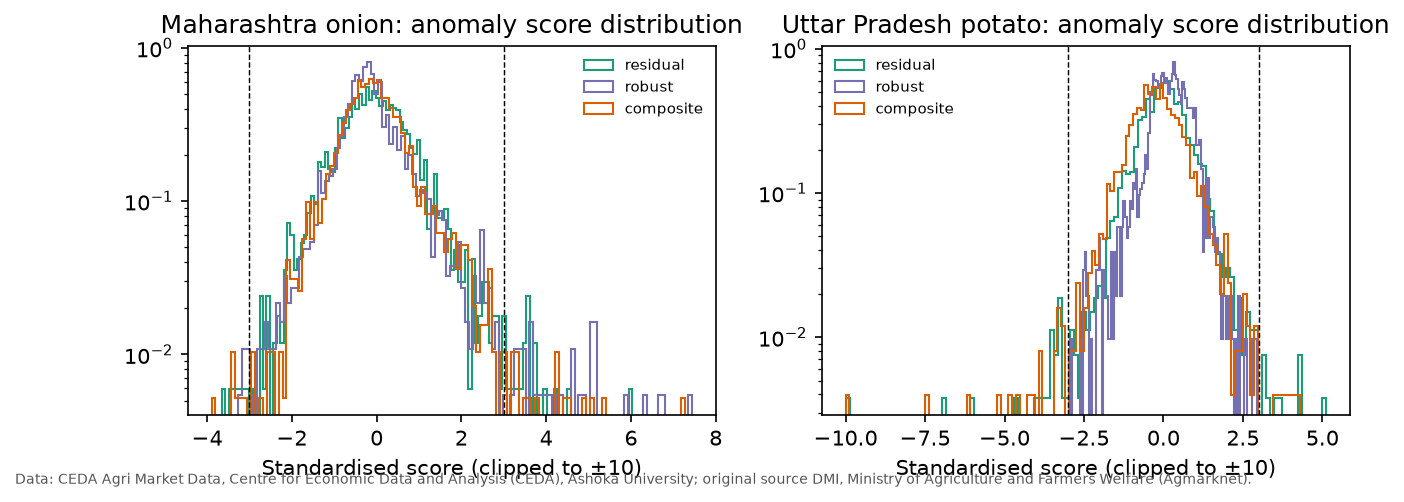

In [6]:
display(Image(filename=str(figs / 'fig15_anomaly_score_distributions.png')))

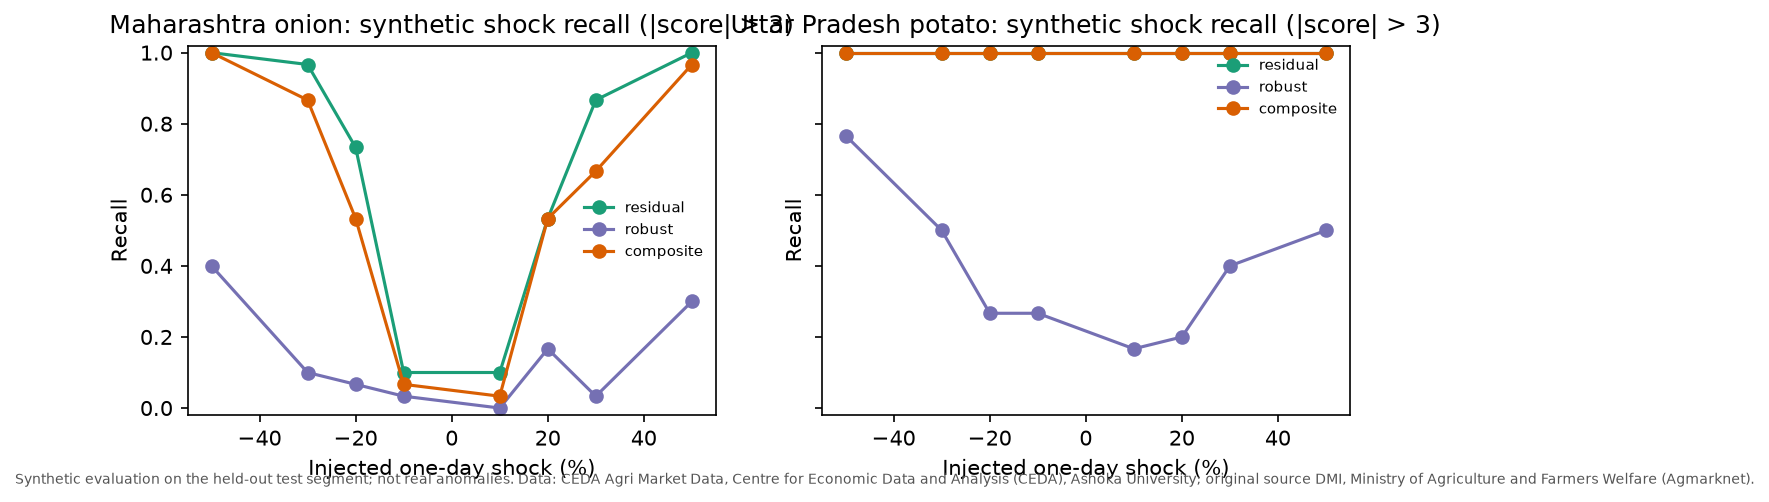

In [7]:
display(Image(filename=str(figs / 'fig16_shock_recall.png')))

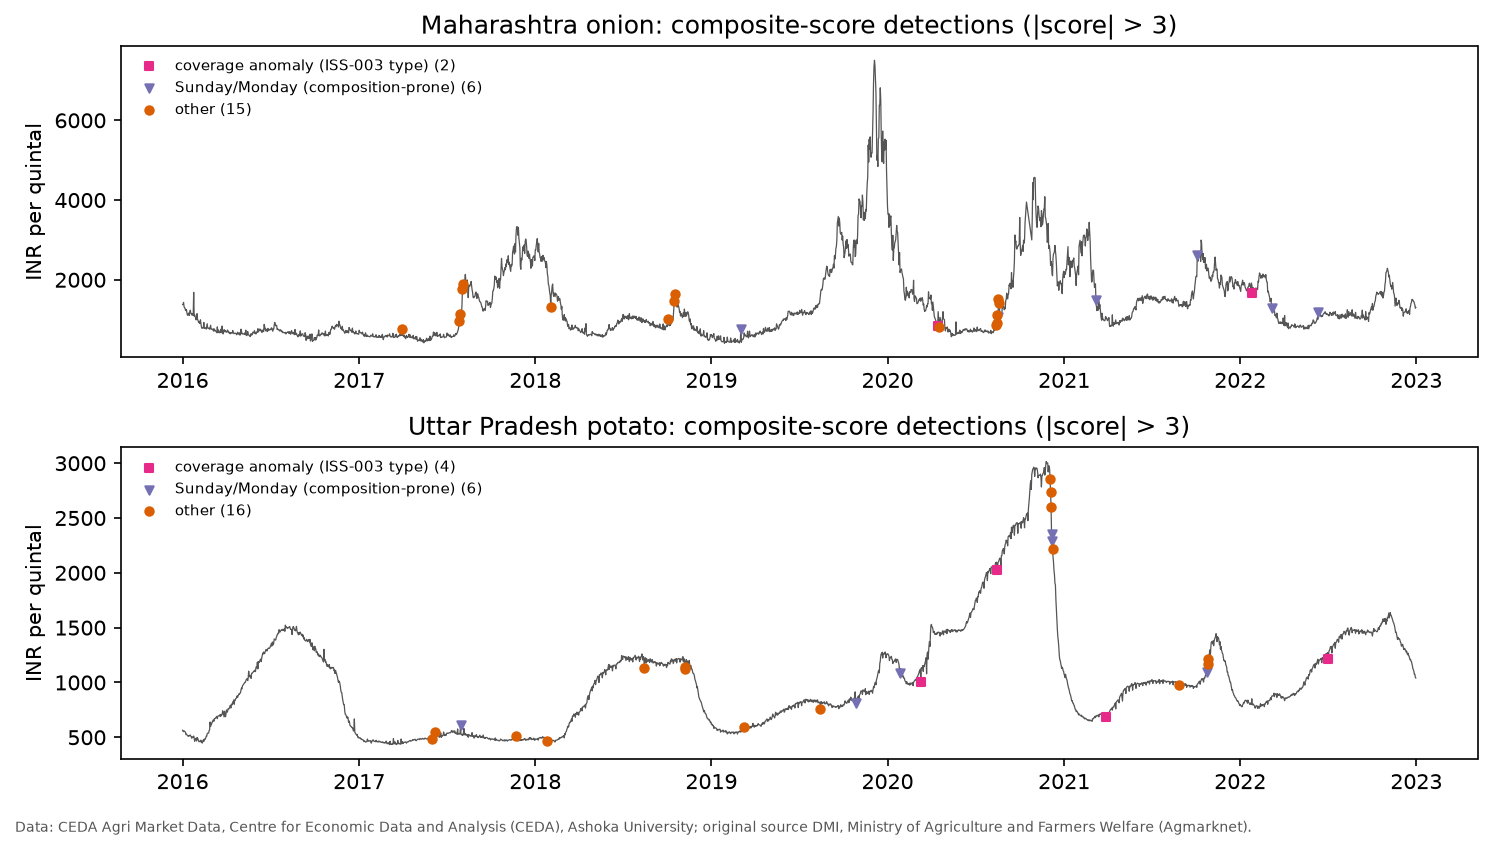

In [8]:
display(Image(filename=str(figs / 'fig17_anomaly_timeline.png')))

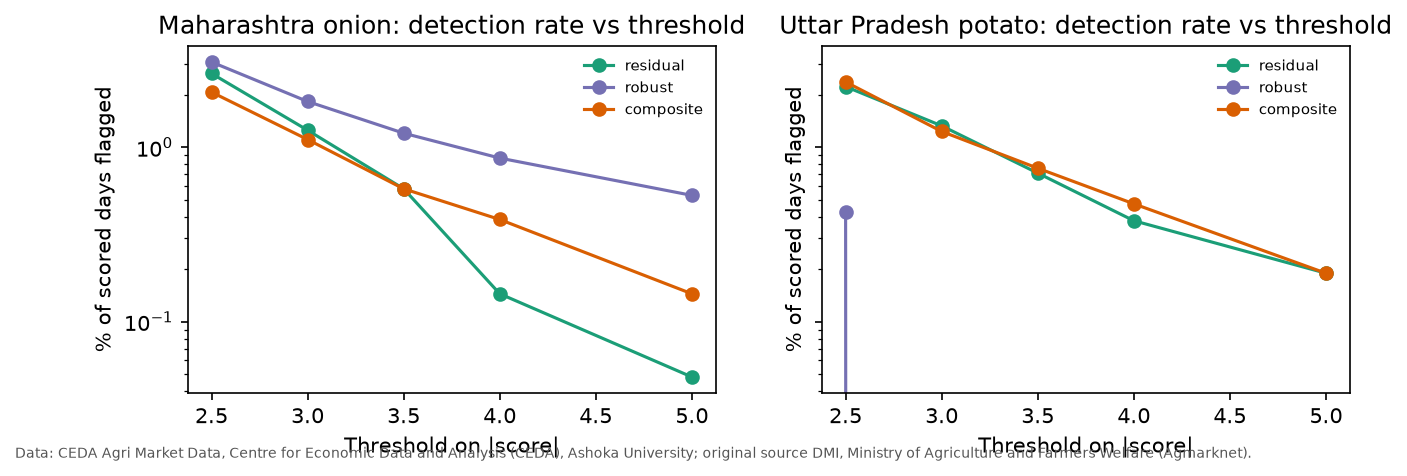

In [9]:
display(Image(filename=str(figs / 'fig18_threshold_sensitivity.png')))